### Revisión analítica de Itô 

(Modelado de ecuaciones diferenciales estocástica bajo el cálculo de Itô)

$\begin{equation} dX_t = f(X_t)dt + g(X_t)dW_t, \end{equation}$ 

donde:
  - $X_t \in \mathbb{R}$ representa un proceso estocástico continuo que describe el estado del sistema a lo largo del tiempo
  - $f$ una función que modela la tendencia media (término de deriva o drift (parte determinista))
  - $g$ una función que modela el ruido del sistema (término de difusión o diffusion (parte aleatoria)) 
  - $W_t$ un proceso de Wiener, tal que $W_t - W_s \sim \mathcal{N}(0, t-s)$ (lo que significa que viene de la suma acumulada de ruidos blancos)

La solución del proceso viene dada por:

$\begin{equation} X_t = X_0 + \int_0^t f(X_s)ds + \int_0^t g(X_s)dW_s, \end{equation}$

donde:
- $\int_0^t f(X_s)ds$ es una integral en el sentido de Riemann/Lebesgue
- $\int_0^t g(X_s)dW_s$ es una integral estocástica de Itô. Además esta integral cumple la condición de martingala ($\mathbb{E}[\int_0^t g(X_s)dW_s] = 0$), asumiendo que $g \in L^2$ ($\mathbb{E} [\int_0^t g^2(X_s)ds] < \infty$)

Lema de Itô ("Regla de la cadena")

Como estamos trabajando con un proceso de Wiener, el cual no es diferenciable en ningún punto debido a su naturaleza, tenemos que usar el lema de Itô para tratar con la integral del término de difusión. Usando la expansión de orden 2 de Taylor acabamos con 
$$ dh(t, X_t) = (\frac{\partial h}{\partial t} + \frac{\sigma_t^2}{2}\frac{\partial^2 h}{\partial x^2})dt + \frac{\partial h}{\partial x} dX_t$$

en nuestra ecuación original $\sigma_t \equiv g(X_t)$

 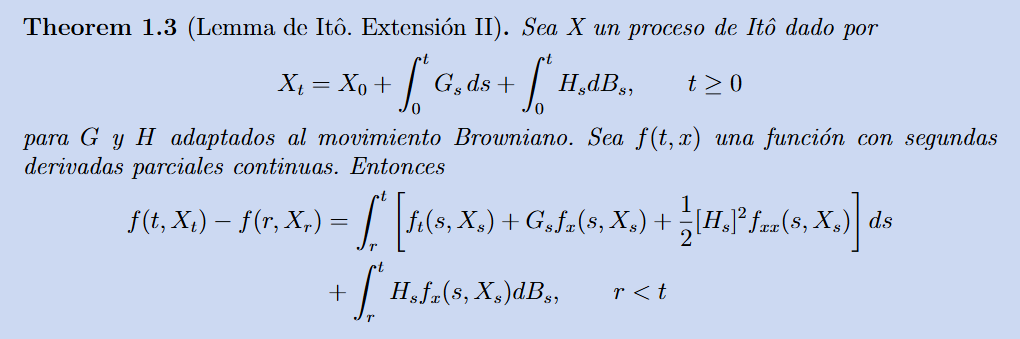

### Langevin sobreamortiguado

Single Particle Tracking (SPT)

Formulación clásica: 

$$ m \frac{d^2 X_t}{dt^2} = -\gamma \frac{dX_t}{dt} + F_{ext} + \xi (t), $$

con $\xi (t)$ un ruido blanco, t.q. $\mathbb{E} [\xi(t)\xi(s)] = 2\gamma k_B T \delta(t-s)$, donde $k_B$ es la constante de Boltzmann y T la temperatura absoluta, $\gamma = 6\pi\eta r_p$ la constante de fricción hidrodinámica de Stokes, $\eta$ la viscosidad dinámica del fluido y $r_p$ el radio hidrodinámico de la partícula.

Según [Simulation of a Brownian particle in an optical trap] se define el problema como: 

$$ m \ddot{x}(t) \text{(inercia)}= -\gamma \dot{x}(t) \text{(fricción)}+ kx(t) \text{(fuerza de restauración)}+ \sqrt{2k_B\gamma}W(t) \text{(ruido blanco)}$$

Aunque al trabajar en numeros de Reynold muy bajos ($Re \ll 1$) el término de la inercia es 0, lo que provoca que la partícula solo se mueva por difusión o mediante movimientos no simétricos de alguna parte de su estructura o el propio flujo del canal donde se mueva, acabando con la siguiente formulación:

$$ \gamma \frac{dX_t}{dt} = F_{ext} + \xi (t) \Rightarrow dX_t = \frac{F_{ext}}{\gamma}dt + \frac{1}{\gamma} \xi(t)dt $$

de esta ecuación podemos pasar a: 

$$ dX_t = v_{flujo} dt + \sqrt{2D}\, dW_t, $$

con $\frac{1}{\gamma}\xi(t)dt = \sqrt{2D}dW_t$ y $\frac{F_ext}{\gamma}$

Asociándolo con la formulación de Itô, de la forma $dX_t = \mu dt + \sigma dW_t$ (siendo f y g 2 constantes $\mu$ y $\sigma$ respectivamente) tenemos que $\mu = v_{\text{flujo}}$ y $\sigma = \sqrt{2D}$, siendo $D$ el coeficiente de difusión translacional 

$$ D = \frac{k_BT}{\gamma = 6\pi\eta r_p} \Rightarrow \sigma = \sqrt{\frac{2k_BT}{6\pi\eta r_p}} $$


Finalmente, para un sistema en reposo (sin fuerzas externas), el problema se reduce a:

$$ dX_t = \sqrt{2D}\, dW_t $$

### Formalismo de Titsias

(Procesos Gaussianos Dispersos / Sparse Gaussian Processes (SVGP))

Formulación clásica de un Proceso Gaussiano (GP):

$$f(x) \sim \mathcal{GP}(m(x), k(x, x')),$$

donde:
- $m(x)$ es la función de media (típicamente $m(x) = 0$)
- $k(x, x')$ es la función de covarianza o kernel que modela la correlación espacial/temporal entre puntos

Para un conjunto de $N$ observaciones discretas, la inferencia exacta requiere invertir la matriz de covarianza completa $K_{NN} \in \mathbb{R}^{N \times N}$, lo que supone un coste computacional de $\mathcal{O}(N^3)$, intratable para series temporales densas o prolongadas.

Variables inductoras (*Inducing Variables*):

Michalis Titsias (2009) propuso introducir un conjunto de $M \ll N$ pseudo-entradas espaciales $Z = \{z_m\}_{m=1}^M$ y sus correspondientes valores funcionales latentes $u = f(Z) \in \mathbb{R}^M$. 

La distribución conjunta *a priori* entre las funciones en las observaciones $f = f(X)$ y los puntos inductores $u$ viene dada por:

$$p(f, u) = p(f \mid u)\,p(u),$$

donde:
- $p(u) = \mathcal{N}(u \mid 0, K_{uu})$, con $K_{uu} = k(Z, Z) \in \mathbb{R}^{M \times M}$
- $p(f \mid u) = \mathcal{N}\left(f \mid K_{fu}K_{uu}^{-1}u, \; K_{ff} - K_{fu}K_{uu}^{-1}K_{uf}\right)$, con $K_{fu} = k(X, Z)$ y $K_{ff} = k(X, X)$

Aproximación variacional:

Para aproximar la distribución posterior real $p(f, u \mid y)$, se define una distribución variacional estructurada $q(f, u) = p(f \mid u)\,q(u)$, donde $q(u)$ se parametriza como una gaussiana con parámetros a optimizar:

$$q(u) = \mathcal{N}(u \mid m, S),$$

con $m \in \mathbb{R}^M$ el vector de medias variacionales y $S \in \mathbb{R}^{M \times M}$ la matriz de covarianza variacional.

Al marginalizar $u$, la distribución variacional sobre las funciones observadas resulta analítica:

$$q(f) = \int p(f \mid u)\,q(u)\,du = \mathcal{N}(f \mid \tilde{\mu}, \tilde{\Sigma}),$$

donde:
- $\tilde{\mu} = K_{fu}K_{uu}^{-1}m$
- $\tilde{\Sigma} = K_{ff} - K_{fu}K_{uu}^{-1}K_{uf} + K_{fu}K_{uu}^{-1}S K_{uu}^{-1}K_{uf}$

Cota Inferior de la Evidencia (ELBO):

El aprendizaje de los hiperparámetros, la posición de los inductores $Z$ y los parámetros variacionales $(m, S)$ se realiza maximizando la cota ELBO:

$$ \log p(y) \ge \mathcal{L}_{\text{ELBO}} = \sum_{i=1}^N \mathbb{E}_{q(f_i)}\left[\log p(y_i \mid f_i)\right] - \text{KL}\left(q(u) \,\parallel\, p(u)\right), $$

donde:
- $\sum_{i=1}^N \mathbb{E}_{q(f_i)}\left[\log p(y_i \mid f_i)\right]$ es el término de ajuste a los datos (verosimilitud), separable punto a punto, lo que posibilita el entrenamiento por mini-batches.
- $\text{KL}\left(q(u) \,\parallel\, p(u)\right)$ es la divergencia de Kullback-Leibler entre la aproximación variacional $q(u)$ y el prior $p(u)$, que actúa como regularizador y se calcula analíticamente sobre el espacio reducido $M$:

$$ \text{KL}\left(q(u) \,\parallel\, p(u)\right) = \frac{1}{2} \left[ \text{Tr}(K_{uu}^{-1}S) + m^T K_{uu}^{-1}m - M + \log\frac{\det K_{uu}}{\det S} \right] $$

Reducción de complejidad:

Al invertir únicamente la matriz de inductores $K_{uu} \in \mathbb{R}^{M \times M}$, el coste temporal del algoritmo pasa de $\mathcal{O}(N^3)$ a:

$$ \mathcal{O}(NM^2), $$

escalando de manera estrictamente lineal respecto al volumen de datos observados $N$.